# Section 3 Pilot — Domestic vs. Re-Export Decomposition

Question: how much of U.S. AI-related exports are genuinely U.S.-produced (domestic exports) versus simply imported and re-exported (foreign / re-exports)?

The paper currently hypothesizes (§3 last paragraph) that AI-related products are being imported into the U.S. and re-exported to Mexico. This notebook is the first direct test of that hypothesis.

Inputs:
- `All-country-exports-DF.parquet` from the `us-exports-hs10` repo's `data/exports-hs10-DF/` folder (currently `c:\heroku\us-exports-hs10\`; the path cell below resolves it)
- `TOTALexports-combined-DF.parquet` (same folder)
- `data-input/hs10_classification_imports_exports.csv` for AI classification

Outputs: figures + tables (saved to `paper/figures/` and printed) covering:
1. Overall domestic vs re-export shares (totals)
2. AI-related vs non-AI domestic/re-export split
3. By AI product category (Compute Hardware, Electrical Power, etc.)
4. By destination country (Mexico, Canada, China, etc.)
5. Time trend 2022-2026

**Pilot only** — no paper-output writes (no LaTeX macros, no `paper/tables/` updates).


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


In [ ]:
# Paths — the DF parquets live in the sister us-exports-hs10 repo, which has
# moved between drives. Take the first location that actually has the files.
DF_DIR_CANDIDATES = [
    '../data-input',                                    # local copy, if one is ever made
    r"c:\heroku\us-exports-hs10\data\exports-hs10-DF",  # current location
    r"..\..\us-exports-hs10\data\exports-hs10-DF",      # old c:\github location
]

DF_DATA_DIR = next((p for p in DF_DIR_CANDIDATES
                    if os.path.exists(os.path.join(p, "TOTALexports-combined-DF.parquet"))), None)

if DF_DATA_DIR is None:
    raise FileNotFoundError(
        "TOTALexports-combined-DF.parquet not found in any of: "
        + ", ".join(DF_DIR_CANDIDATES))

ALL_FILE   = os.path.join(DF_DATA_DIR, "All-country-exports-DF.parquet")
TOTAL_FILE = os.path.join(DF_DATA_DIR, "TOTALexports-combined-DF.parquet")
CLASS_FILE = "../data-input/hs10_classification_imports_exports.csv"

assert os.path.exists(ALL_FILE),   f"missing: {ALL_FILE}"
assert os.path.exists(TOTAL_FILE), f"missing: {TOTAL_FILE}"

print("DF data directory:", DF_DATA_DIR)


In [3]:
# Load TOTAL series for the headline split
tot = pd.read_parquet(TOTAL_FILE)
tot["ALL_VAL_MO"] = tot["ALL_VAL_MO"].astype(float)
tot["E_COMMODITY"] = tot["E_COMMODITY"].astype(str).str.zfill(10)
tot["HS10"] = tot["E_COMMODITY"].astype("int64")
tot["HS2"]  = tot["E_COMMODITY"].str[:2]
tot["time"] = pd.to_datetime(tot["time"], format="%Y-%m")
tot = tot[~tot["HS2"].isin(["27","71","98","99"])]

# Load classification
mat = pd.read_csv(CLASS_FILE)
mat = mat.rename(columns={"hs10_code":"HS10"})
tot = tot.merge(mat[["HS10","relevance","primary_category"]], on="HS10", how="left")

# Filter to pilot range only
tot = tot[tot["time"] >= "2022-01-01"]
print(f"TOTAL rows after filter: {len(tot):,}")
print(f"Date range: {tot['time'].min().date()} to {tot['time'].max().date()}")
print(f"export_type breakdown:")
print(tot["export_type"].value_counts())


TOTAL rows after filter: 1,317,346
Date range: 2022-01-01 to 2026-03-01
export_type breakdown:
export_type
Total Exports       461168
Domestic Exports    456751
Re-Exports          399427
Name: count, dtype: int64


## 1. Headline: domestic vs re-export shares (TOTAL, all products, 2022-2025)

In [4]:
# Yearly totals by export type
tot["year"] = tot["time"].dt.year
yearly = tot.groupby(["year","export_type"])["ALL_VAL_MO"].sum().unstack() / 1e9
yearly = yearly[["Total Exports","Domestic Exports","Re-Exports"]]
yearly["Re-Export Share %"] = 100 * yearly["Re-Exports"] / yearly["Total Exports"]
yearly["Domestic Share %"]  = 100 * yearly["Domestic Exports"] / yearly["Total Exports"]
print("All U.S. exports (excluding HS2 27/71/98/99):")
print(yearly.round(2))


All U.S. exports (excluding HS2 27/71/98/99):
export_type  Total Exports  Domestic Exports  Re-Exports  Re-Export Share %  \
year                                                                          
2022              1,534.75          1,263.15      271.60              17.70   
2023              1,551.88          1,268.03      283.86              18.29   
2024              1,601.49          1,291.51      309.97              19.36   
2025              1,648.45          1,306.46      341.99              20.75   
2026                427.29            327.84       99.45              23.27   

export_type  Domestic Share %  
year                           
2022                    82.30  
2023                    81.71  
2024                    80.64  
2025                    79.25  
2026                    76.73  


## 2. AI-related vs non-AI: domestic vs re-export split

In [5]:
# By AI relevance
ai_split = tot.groupby(["year","relevance","export_type"])["ALL_VAL_MO"].sum().unstack(fill_value=0) / 1e9
ai_split = ai_split[["Total Exports","Domestic Exports","Re-Exports"]]
ai_split["Re-Export Share %"] = 100 * ai_split["Re-Exports"] / ai_split["Total Exports"]
print("By AI relevance:")
print(ai_split.round(2))

print()
print("Re-export share comparison (AI High vs non-AI), by year:")
pivot = (100 * tot.groupby(["year","relevance","export_type"])["ALL_VAL_MO"].sum().unstack()
                       .pipe(lambda d: d["Re-Exports"] / d["Total Exports"]))
print(pivot.unstack().round(2))


By AI relevance:
export_type     Total Exports  Domestic Exports  Re-Exports  Re-Export Share %
year relevance                                                                
2022 High              222.42            126.46       95.96              43.14
     Low             1,014.31            878.22      136.09              13.42
     Medium            298.02            258.46       39.56              13.27
2023 High              221.48            129.96       91.52              41.32
     Low             1,034.77            882.80      151.97              14.69
     Medium            295.63            255.26       40.37              13.65
2024 High              257.06            149.41      107.65              41.88
     Low             1,045.07            885.45      159.62              15.27
     Medium            299.36            256.66       42.70              14.26
2025 High              297.88            159.61      138.26              46.42
     Low             1,058.61      

## 3. By AI product category

In [6]:
# High-relevance only, by category
cat_data = tot[tot["relevance"] == "High"].copy()
cat = cat_data.groupby(["primary_category","export_type"])["ALL_VAL_MO"].sum().unstack(fill_value=0) / 1e9
cat = cat[["Total Exports","Domestic Exports","Re-Exports"]]
cat["Re-Export Share %"] = 100 * cat["Re-Exports"] / cat["Total Exports"]
cat = cat.sort_values("Total Exports", ascending=False)
print("AI High-relevance categories, 2022-2026 cumulative:")
print(cat.round(2))


AI High-relevance categories, 2022-2026 cumulative:
export_type             Total Exports  Domestic Exports  Re-Exports  \
primary_category                                                      
Compute_Hardware               551.82            237.83      313.99   
Electrical_Power               279.92            205.12       74.80   
Networking_Telecom             135.27             61.34       73.93   
Cooling_HVAC                   102.50             84.93       17.58   
Building_Structure              12.30             10.94        1.36   
Specialty_Materials              3.03              2.59        0.44   
Fire_Safety_Security             2.33              1.92        0.41   
Maintenance_Operations           2.06              1.54        0.52   

export_type             Re-Export Share %  
primary_category                           
Compute_Hardware                    56.90  
Electrical_Power                    26.72  
Networking_Telecom                  54.66  
Cooling_HVAC     

## 4. By destination country (focus on the Mexico re-export hypothesis)

In [7]:
# Load by-country file
cty = pd.read_parquet(ALL_FILE)
cty["ALL_VAL_MO"] = cty["ALL_VAL_MO"].astype(float)
cty["E_COMMODITY"] = cty["E_COMMODITY"].astype(str).str.zfill(10)
cty["HS10"] = cty["E_COMMODITY"].astype("int64")
cty["HS2"]  = cty["E_COMMODITY"].str[:2]
cty["time"] = pd.to_datetime(cty["time"], format="%Y-%m")
cty = cty[~cty["HS2"].isin(["27","71","98","99"])]
cty = cty.merge(mat[["HS10","relevance","primary_category"]], on="HS10", how="left")
cty = cty[cty["time"] >= "2022-01-01"]
cty["year"] = cty["time"].dt.year
print(f"By-country rows: {len(cty):,}")
print(f"Countries: {cty['CTY_NAME'].nunique()}")


By-country rows: 17,382,898
Countries: 31


In [8]:
# Re-export share of AI-High exports, by destination, 2024-2025 combined
recent = cty[(cty["year"].isin([2024, 2025])) & (cty["relevance"] == "High")].copy()
by_cty = recent.groupby(["CTY_NAME","export_type"])["ALL_VAL_MO"].sum().unstack(fill_value=0) / 1e9

if "Total Exports" in by_cty.columns:
    by_cty["Re-Export Share %"] = 100 * by_cty.get("Re-Exports", 0) / by_cty["Total Exports"].replace(0, np.nan)
    by_cty = by_cty.sort_values("Total Exports", ascending=False)
    print("AI-High exports to top destinations, 2024-2025 (excluding aggregates):")
    print(by_cty.head(15).round(2))


AI-High exports to top destinations, 2024-2025 (excluding aggregates):
export_type     Domestic Exports  Re-Exports  Total Exports  Re-Export Share %
CTY_NAME                                                                      
MEXICO                     49.53      108.42         157.95              68.64
EUROPEAN UNION             43.75       31.69          75.44              42.00
CANADA                     37.12       20.77          57.89              35.87
CHINA                      27.13        7.98          35.12              22.73
TAIWAN                     20.80       12.35          33.16              37.25
MALAYSIA                   17.07        9.05          26.12              34.65
NETHERLANDS                10.77       11.29          22.06              51.19
SINGAPORE                   9.35        6.39          15.74              40.61
GERMANY                     9.74        4.86          14.60              33.28
UNITED KINGDOM              9.90        4.52          14.42 

## 5. Time trend — re-export share of AI exports, monthly 2022-2026

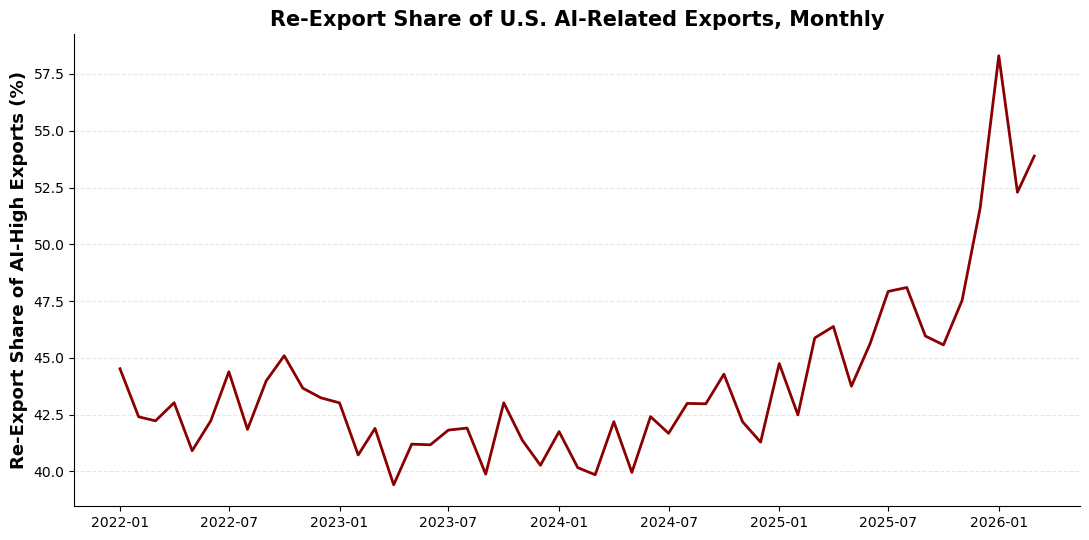


Yearly average re-export share of AI-High exports:
time
2022   43.12
2023   41.30
2024   41.81
2025   46.29
2026   54.83
Name: Re-Export Share %, dtype: float64


In [9]:
# Monthly re-export share of AI-High exports (using TOTAL row series)
ai_high_monthly = tot[tot["relevance"] == "High"].groupby(["time","export_type"])["ALL_VAL_MO"].sum().unstack(fill_value=0)
ai_high_monthly["Re-Export Share %"] = 100 * ai_high_monthly["Re-Exports"] / ai_high_monthly["Total Exports"]

# Plot
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(ai_high_monthly.index, ai_high_monthly["Re-Export Share %"], color="#8B0000", linewidth=2)
ax.set_ylabel("Re-Export Share of AI-High Exports (%)", fontsize=13, fontweight="bold")
ax.set_title("Re-Export Share of U.S. AI-Related Exports, Monthly", fontsize=15, fontweight="bold")
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# Print yearly averages
yearly_share = ai_high_monthly.groupby(ai_high_monthly.index.year)["Re-Export Share %"].mean()
print()
print("Yearly average re-export share of AI-High exports:")
print(yearly_share.round(2))


## Summary
After running this notebook, the key numbers to extract for the paper §3 narrative:

1. **What fraction of all U.S. AI-related exports are re-exports?** (yearly, 2022-2025)
2. **Is the re-export share rising or stable?**
3. **Which destinations have the highest re-export share?** (Mexico specifically — does the data confirm the paper's hypothesis?)
4. **Which AI categories are most re-export heavy?** (Likely Compute Hardware, given it's the most tradeable AI input)

If results show a meaningful re-export story (>20% share for Mexico, or rising trend), justify updating notebook 10 / §3 with the split. Otherwise, document as a null result.
